# Regresión: LightGBM

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from ModeladoRegresion import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_REG, VARIANTES, N_ITER_REG, RUTA_FASE1_REG,
    cargar_split, separar_x_y_reg, crear_cv_reg, resumen_target, dispositivo_reg, describir_espacio_reg,
    ejecutar_fase1_reg, formatear_tabla_cv_reg, tabla_hiperparametros_reg, graficar_variantes, evaluar_smearing,
    elegir_variante, guardar_fase1_reg, formatear_hiperparametros,
)

CLAVE = "lightgbm"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_reg(CLAVE),
}, name=NOMBRES_REG[CLAVE]).to_frame()

,LightGBM
USAR_GPU,False
GPU detectada por librería,ninguna
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y_reg(df_train)
cv = crear_cv_reg(SEED)

resumen_target(y_train)

,Filas,Media,Mediana,DE,Asimetría,Ceros (%),BDI ≥ 14 (%)
Conjunto,,,,,,,
Train,3848,7.3,5.0,7.75,1.9,10.5,16.4


### Variantes del Target

| Variante | Qué se entrena | Cómo se predice |
|---|---|---|
| **a) Nativo** | `bdi_total` sin transformar (pérdida cuadrática) | Predicción directa |
| **b) sqrt** | $\sqrt{y}$ | $\hat y = \frac{1}{n}\sum_i (\hat z + e_i)^2$ (smearing) |
| **c) log1p** | $\log(1+y)$ | $\hat y = \frac{1}{n}\sum_i \left(e^{\hat z + e_i} - 1\right)$ (smearing) |
| **d) Pérdida Poisson** | `bdi_total` sin transformar, con pérdida (deviance) Poisson: `objective="poisson"` | Predicción directa en la escala de la media |

En las cuatro, la predicción final se recorta a $[0, 63]$.

**Sesgo de retransformación.** En sqrt y log1p el modelo aprende la media **en la escala transformada**, $E[g(y)\mid x]$, y al deshacer la transformación se obtiene $g^{-1}(E[g(y)\mid x])$, que **no** es $E[y\mid x]$. Como las inversas ($z^2$ y $e^z - 1$) son convexas, por la desigualdad de Jensen la predicción retransformada **subestima la media** del BDI, más cuanto más dispersos son los residuos. Como el RMSE en puntos BDI premia acertar la media condicional, ese sesgo es un error sistemático.

**Corrección de smearing (Duan, 1983).** Se usan los residuos de entrenamiento en la escala transformada, $e_i = g(y_i) - \hat z_i$, como muestra de los errores posibles: $\hat y = \frac{1}{n}\sum_{i} g^{-1}(\hat z + e_i)$. `RegresorBDI` calcula los residuos **solo con los datos de entrenamiento de cada fold**. En los árboles los residuos de entrenamiento son más pequeños que los de datos nuevos (el modelo se ajusta a ellos), así que la corrección es parcial.

La **pérdida Poisson** no tiene este problema: no transforma $y$, sino que ajusta la media directamente con una pérdida pensada para conteos no negativos y asimétricos, así que no necesita smearing. Todas las métricas se calculan en puntos BDI.

### Espacio de Búsqueda

Mismos rangos que en la clasificación (versión `Regressor`). Se exploraron 25 combinaciones por variante: número de árboles (100 a 600), número de hojas (4 a 31), profundidad máxima (sin límite, 3, 5 o 7), tamaño mínimo de las hojas (10 a 100), muestreo de filas y columnas (0.6 a 1) y tasa de aprendizaje en escala logarítmica (0.01 a 0.2).

In [4]:
describir_espacio_reg(CLAVE).style.set_caption(f"Combinaciones por variante: {N_ITER_REG[CLAVE]}")

,Valores
Hiperparámetro,
n_estimators,entero entre 100 y 600
num_leaves,entero entre 4 y 31
max_depth,"-1, 3, 5, 7"
learning_rate,log-uniforme entre 0.01 y 0.2
min_child_samples,entero entre 10 y 100
subsample,uniforme entre 0.6 y 1
colsample_bytree,uniforme entre 0.6 y 1


### Validación Cruzada por Variante

Para cada variante se ejecuta un `RandomizedSearchCV` **solo sobre el train**, con los mismos folds y `scoring` RMSE (`neg_root_mean_squared_error`). El RMSE, el MAE y el R² se calculan siempre en puntos BDI, nunca en la escala transformada.

In [5]:
tabla, pipelines, hiperparametros = ejecutar_fase1_reg(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo             RMSE = 6.9020 ± 0.4824  R² = 0.2005  (7 s)
✓ sqrt + smearing    RMSE = 6.8921 ± 0.4911  R² = 0.2029  (5 s)
✓ log1p + smearing   RMSE = 6.8835 ± 0.4986  R² = 0.2051  (4 s)
✓ Pérdida Poisson    RMSE = 6.8890 ± 0.4924  R² = 0.2037  (3 s)


In [6]:
vista = formatear_tabla_cv_reg(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(0)
vista.rename(index=VARIANTES)

,RMSE,MAE,R²,Tiempo (s)
Variante,,,,
Nativo,6.902 ± 0.482,4.909 ± 0.182,0.200 ± 0.017,7.0
sqrt + smearing,6.892 ± 0.491,4.878 ± 0.187,0.203 ± 0.018,5.0
log1p + smearing,6.883 ± 0.499,4.859 ± 0.185,0.205 ± 0.017,4.0
Pérdida Poisson,6.889 ± 0.492,4.902 ± 0.188,0.204 ± 0.017,3.0


log1p obtiene el menor RMSE (6.883 ± 0.499) y el mayor R² (0.205), seguida de la pérdida Poisson (6.889), sqrt (6.892) y el nativo (6.902). Las cuatro variantes están a menos de 0.02 puntos, y el nativo es la única que no mejora a la regresión lineal (6.900).

In [7]:
# Mejores hiperparámetros por variante
tabla_hiperparametros_reg(hiperparametros)

,colsample_bytree,learning_rate,max_depth,min_child_samples,n_estimators,num_leaves,subsample
Variante,,,,,,,
Nativo,0.9215,0.01749,3,71,430,29,0.6488
sqrt + smearing,0.9215,0.01749,3,71,430,29,0.6488
log1p + smearing,0.9443,0.01021,7,36,236,8,0.8770
Pérdida Poisson,0.9215,0.01749,3,71,430,29,0.6488


El nativo, sqrt y Poisson eligieron exactamente la misma configuración: 430 árboles de profundidad 3, `learning_rate` = 0.017 y al menos 71 observaciones por hoja. La profundidad 3 limita las hojas efectivas a 8, aunque `num_leaves` = 29. log1p prefiere menos árboles (236), más profundos (7) pero con solo 8 hojas y una tasa de aprendizaje menor (0.010). En todos los casos son modelos fuertemente regularizados.

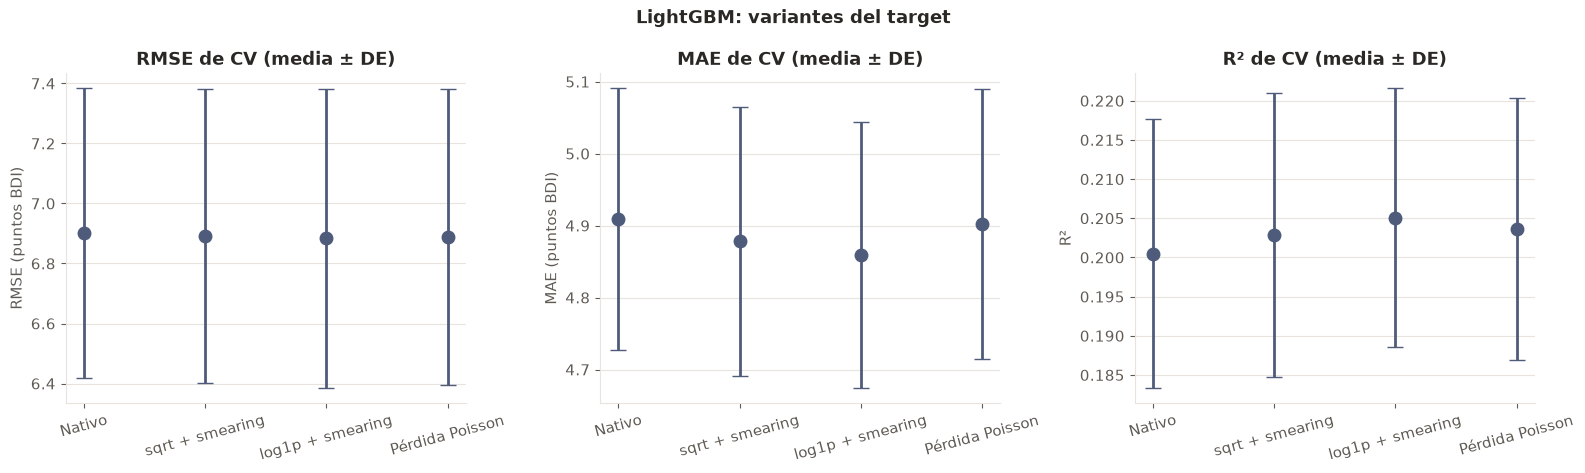

In [8]:
fig = graficar_variantes(tabla, NOMBRES_REG[CLAVE])
plt.show()

La gráfica muestra cuatro variantes equivalentes: sus diferencias de RMSE son una fracción mínima de la desviación entre folds.

### Sesgo de Retransformación: Efecto del Smearing

Con la mejor variante transformada (sqrt o log1p) se calculan predicciones *out-of-fold* (mismos folds, solo train) **con y sin** smearing. Sin la corrección, la media predicha debería quedar por debajo de la media real del BDI.

In [9]:
variante_t, tabla_smearing = evaluar_smearing(tabla, pipelines, X_train, y_train, cv)
tabla_smearing.round(3)

,Media,Sesgo medio,RMSE,MAE,R²
Out-of-fold (log1p + smearing),,,,,
BDI real,7.302,0.000,NaN,NaN,NaN
Sin smearing,4.999,-2.303,7.346,4.670,0.100
Con smearing,7.129,-0.173,6.902,4.859,0.206


Sin smearing, la media predicha con log1p es 5.00, 2.30 puntos por debajo de la real, y el R² cae a 0.100. Con la corrección, la media sube a 7.13, el RMSE baja de 7.346 a 6.902 y el R² sube a 0.206. Queda un sesgo de −0.17 puntos, porque la corrección con residuos de entrenamiento es parcial en el boosting.

### Selección del Mejor Modelo LightGBM

Se elige la variante con **menor RMSE medio de CV**.

**Regla de empate:** si una variante más simple (nativo < sqrt < log1p < Poisson) queda a menos de una desviación estándar de CV de la ganadora, se elige la más simple.

In [10]:
variante_ganadora, explicacion = elegir_variante(tabla)

pd.Series({
    "Variante ganadora": VARIANTES[variante_ganadora],
    "RMSE de CV": f"{tabla.loc[variante_ganadora, 'RMSE media']:.4f} ± {tabla.loc[variante_ganadora, 'RMSE DE']:.4f}",
    "MAE de CV": f"{tabla.loc[variante_ganadora, 'MAE media']:.4f} ± {tabla.loc[variante_ganadora, 'MAE DE']:.4f}",
    "R² de CV": f"{tabla.loc[variante_ganadora, 'R² media']:.4f} ± {tabla.loc[variante_ganadora, 'R² DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[variante_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_REG[CLAVE]).to_frame()

,LightGBM
Variante ganadora,Nativo
RMSE de CV,6.9020 ± 0.4824
MAE de CV,4.9091 ± 0.1818
R² de CV,0.2005 ± 0.0171
Hiperparámetros,"colsample_bytree=0.9215, learning_rate=0.01749, max_depth=3, min_child_samples=71, n_estimators=430, num_leaves=29, subsample=0.6488"
Criterio,"El menor RMSE medio de CV es el de 'log1p + smearing' (6.8835 ± 0.4986), pero 'Nativo' es más simple y su RMSE (6.9020) está a solo 0.0185 puntos, menos que la desviación estándar de CV de la ganadora (0.4986). Por la regla de empate se elige 'Nativo'."


log1p tiene el menor RMSE medio (6.8835), pero el nativo está a 0.019 puntos (desviación entre folds: 0.499). Por la regla de empate se elige el nativo.

### Guardado

In [11]:
ganador = guardar_fase1_reg(
    CLAVE, tabla, variante_ganadora, pipelines[variante_ganadora],
    hiperparametros[variante_ganadora], explicacion,
)
print(f"✓ Guardado en {RUTA_FASE1_REG / CLAVE}: resultados_cv.csv, ganador.json y {ganador['archivo']}")

✓ Guardado en /workspace/data/processed/modelado/regresion/fase1/lightgbm: resultados_cv.csv, ganador.json y lightgbm_nativo.joblib
